# Task gallery

This notebook shows one example trial from every task in `cogtasks`. Both collections use the Mod-Cog implementation (Khona, Chandra et al. 2023):

- **`cog20`**: the 20 tasks of Yang et al. 2019.
- **`modcog`**: `cog20` plus 22 **int** variants and 40 **seq** variants.

**How to read a panel.**
- **Top: network input.** One row per input unit and one column per 100 ms step. The rows are the fixation cue, then the two 16-unit stimulus rings (modality 1, then 2). Blue is positive and gray is 0. Red is negative, which only input noise produces.
- **Bottom: target output.** At each step the target is either *fix* (keep fixating) or one of 16 *choice* units on the ring. Orange marks the target.
- Dashed lines mark task periods, named along the top. *go* is the response period.

For tasks that sometimes call for no response (the match families, where a non-match means keep fixating), the panel shows the first trial that does call for one. Multitask envs also append one-hot rule inputs, which these panels leave out.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, TwoSlopeNorm

from cogtasks import list_tasks, make_task

N_RING = 16
SURFACE, INK, MUTED, RULE = "#fcfcfb", "#0b0b0b", "#52514e", "#c3c2b7"
# Diverging input map: red (negative noise) - neutral gray at 0 - blue (signal).
INPUT_CMAP = LinearSegmentedColormap.from_list(
    "inputs", [(0, "#e34948"), (0.5, "#f0efec"), (0.75, "#3987e5"), (1, "#104281")]
)
INPUT_NORM = TwoSlopeNorm(vcenter=0, vmin=-1, vmax=1)
TARGET_CMAP = ListedColormap([SURFACE, "#d95926"])
PERIOD_LABELS = {
    "fixation": "fix", "stimulus": "stim", "decision": "go", "stim1": "s1", "stim2": "s2"
}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": RULE, "font.size": 8,
})


def example_trial(name, seed=0, max_tries=50):
    """Inputs, targets, periods and dt of the first trial that calls for a response."""
    env = make_task("modcog", name, seed=seed)
    for _ in range(max_tries):
        env.new_trial()
        task = env.unwrapped
        if task.gt.any():
            break
    periods = sorted(
        (task.start_ind[p], task.end_ind[p], p)
        for p in task.start_ind
        if task.end_ind[p] > task.start_ind[p]
    )
    return task.ob.copy(), task.gt.copy(), periods, task.dt


def draw_trial(ax_in, ax_out, name, seed=0):
    ob, gt, periods, dt = example_trial(name, seed)
    n_steps = len(gt)
    ax_in.imshow(ob.T, aspect="auto", cmap=INPUT_CMAP, norm=INPUT_NORM, interpolation="nearest")
    onehot = np.zeros((1 + N_RING, n_steps))
    onehot[gt, np.arange(n_steps)] = 1
    ax_out.imshow(onehot, aspect="auto", cmap=TARGET_CMAP, vmin=0, vmax=1, interpolation="nearest")

    for ax in (ax_in, ax_out):
        for start, _, _ in periods[1:]:
            ax.axvline(start - 0.5, color=MUTED, lw=0.6, ls=(0, (2, 2)))
    for y in (0.5, N_RING + 0.5):  # fixation | modality 1 | modality 2
        ax_in.axhline(y, color=SURFACE, lw=1.5)
    ax_out.axhline(0.5, color=RULE, lw=0.6)  # fixation | choices

    ax_in.set_yticks([0, 1 + N_RING // 2, 1 + N_RING + N_RING // 2], ["fix", "mod 1", "mod 2"])
    ax_out.set_yticks([0, 1 + N_RING // 2], ["fix", "choice"])
    ax_in.tick_params(axis="x", length=0, labelbottom=False)
    ax_out.set_xticks([0, n_steps - 1], ["0", f"{(n_steps - 1) * dt / 1000:g} s"], fontsize=6)

    top = ax_in.secondary_xaxis("top")
    top.set_xticks(
        [(start + end) / 2 - 0.5 for start, end, _ in periods],
        [PERIOD_LABELS.get(p, p) for _, _, p in periods],
        fontsize=6,
    )
    top.tick_params(length=0, pad=1)
    ax_in.set_title(name, fontsize=9, fontweight="bold", loc="left", pad=12)


def gallery(names, ncols=4, title=None):
    nrows = -(-len(names) // ncols)
    fig = plt.figure(figsize=(ncols * 2.7, nrows * 2.5), layout="constrained")
    panels = fig.subfigures(nrows, ncols, squeeze=False).flat
    # The grid can have more panels than tasks; spare panels stay empty.
    for seed, (name, panel) in enumerate(zip(names, panels, strict=False)):
        ax_in, ax_out = panel.subplots(2, 1, height_ratios=[1 + 2 * N_RING, 1 + N_RING])
        draw_trial(ax_in, ax_out, name, seed=seed)  # a seed per panel, so draws differ
    if title:
        fig.suptitle(title, fontsize=11, fontweight="bold", x=0.01, ha="left")
    plt.show()

## Cog20

The 20 tasks of Yang et al. 2019, in paper order, as Mod-Cog implements them. They come in four families:

- **go / anti**: respond toward the stimulus, or away from it. *rt* variants respond as soon as the stimulus appears. *dly* variants respond after a delay, from memory.
- **dm**: choose the stronger of two stimuli, using modality 1 or 2, a context-cued modality (*ctx*), or both modalities (*multi*). *dly* variants show the stimuli one after another, separated by a delay.
- **dms / dnms**: respond to the test stimulus if it matches the sample (dms) or does not match it (dnms).
- **dmc / dnmc**: the same rule, but matching by category (which half of the ring) rather than by exact angle.

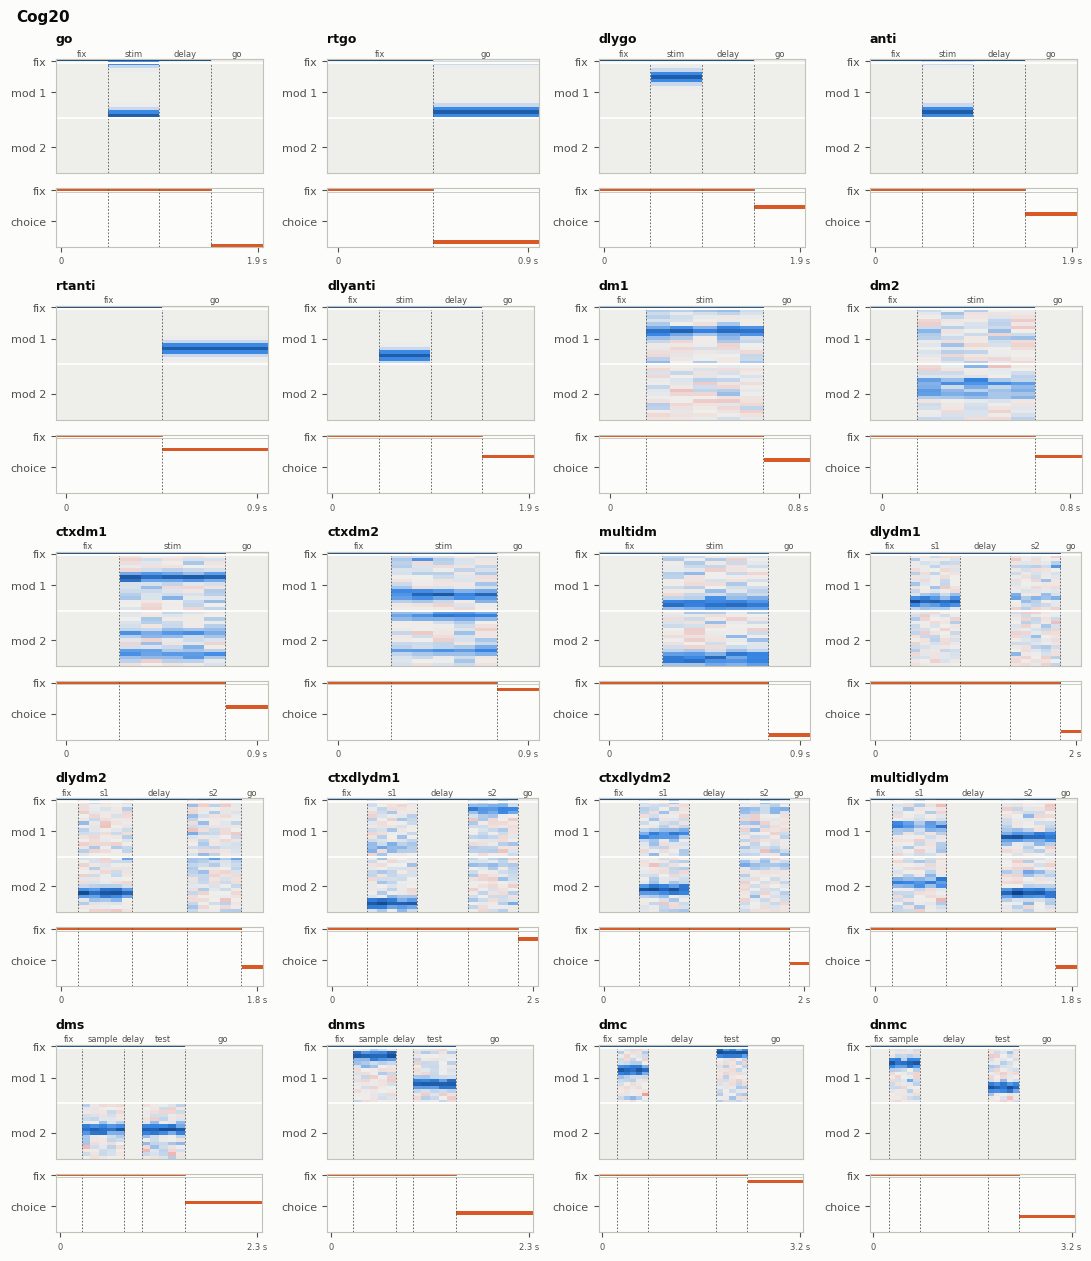

In [2]:
gallery(list_tasks("cog20"), title="Cog20")

## int variants

Each of the 11 delay tasks gains an "int" version. In it, the correct response is offset around the ring from the base task's answer. The offset is set by the delay, clockwise or counter-clockwise depending on *r* or *l*. How the offset is computed differs by family, as implemented upstream:

| family | offset | direction of *r* |
|---|---|---|
| `dlygo`, `dlyanti` | about 2.5 units per 100 ms of a random 0–1.1 s delay | counter-clockwise |
| `dms`, `dnms`, `dmc`, `dnmc` | 1 unit per 100 ms of a random 0–1.1 s delay | clockwise |
| `dlydm*` (all dm delay tasks) | fixed at 5 units, because the delay is fixed at 500 ms | clockwise |

To read the panels, compare where the stimulus sits with where the target sits.

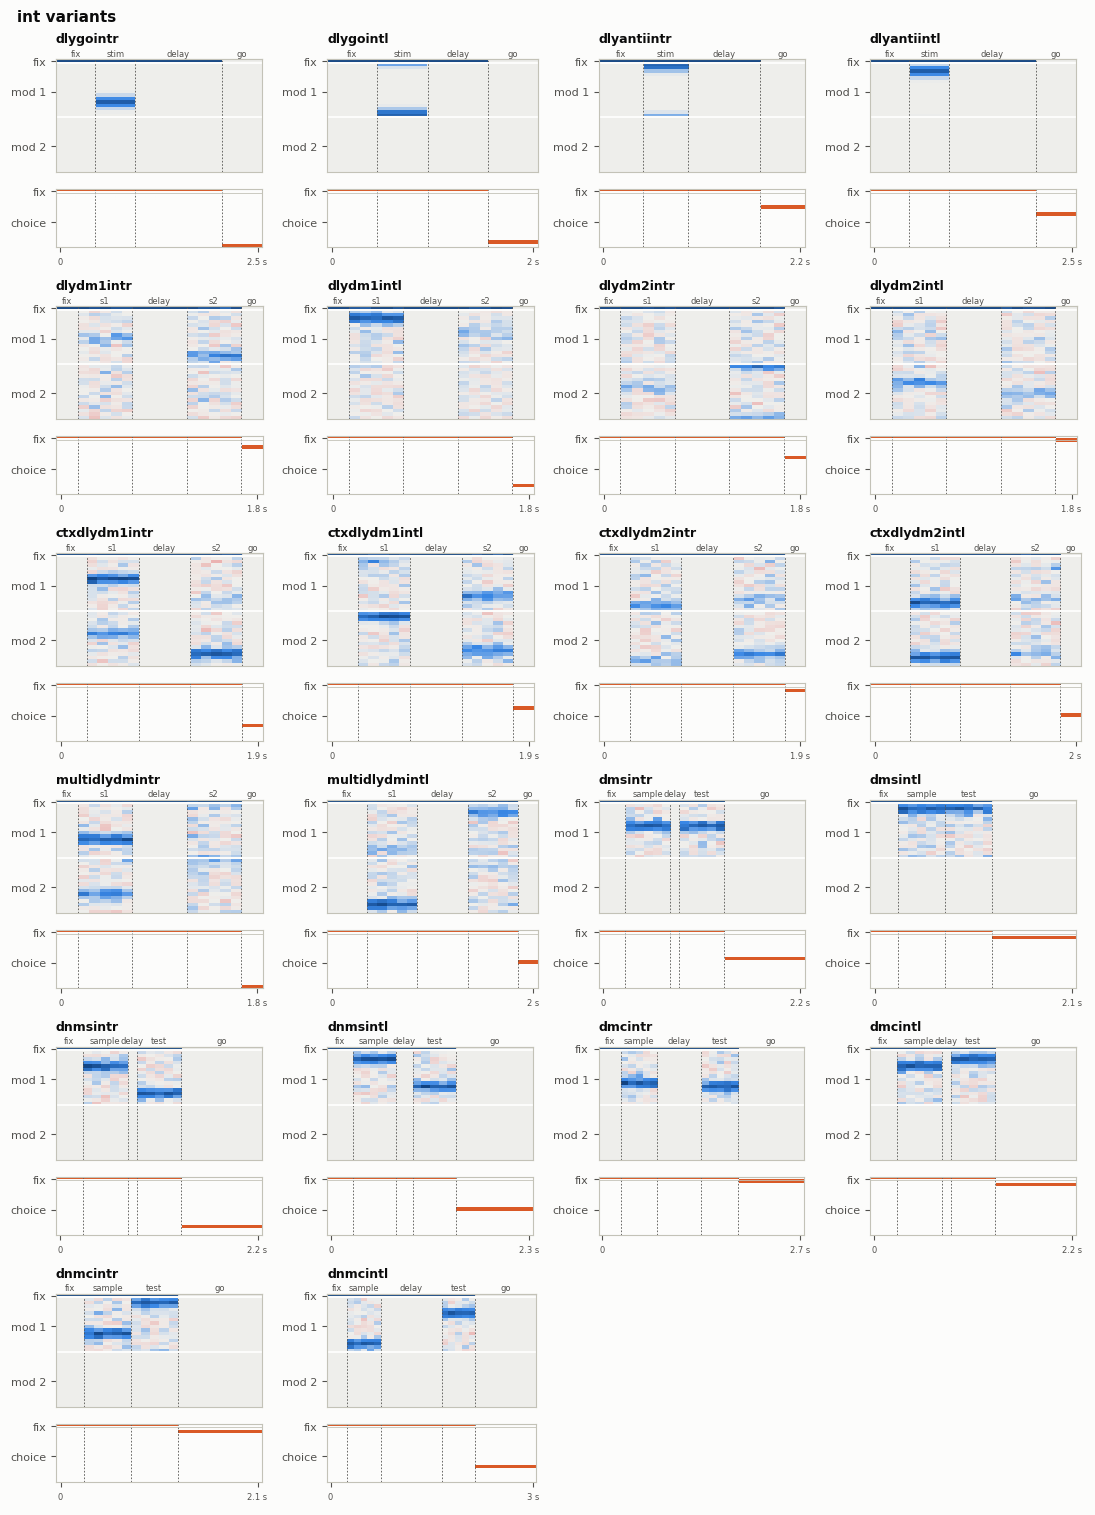

In [3]:
modcog = list_tasks("modcog")
gallery([t for t in modcog if t.endswith(("intr", "intl"))], title="int variants")

## seq variants

All 20 base tasks gain a "seq" version. The response is no longer a single choice. Over a longer response period, the target moves one unit around the ring per step, clockwise (*r*) or counter-clockwise (*l*), starting from the base task's answer.

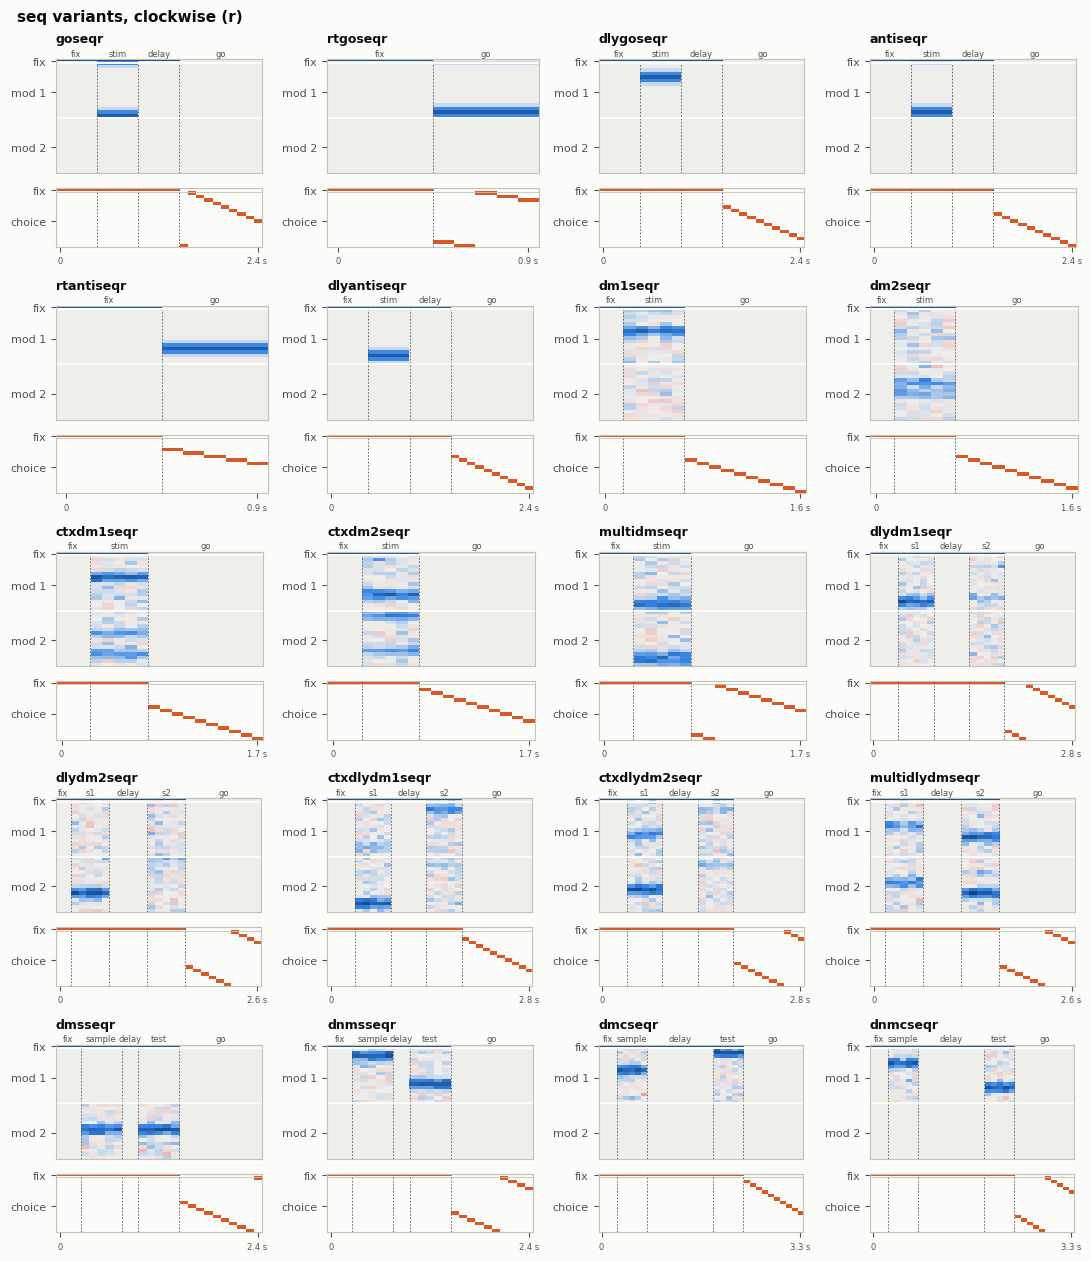

In [4]:
gallery([t for t in modcog if t.endswith("seqr")], title="seq variants, clockwise (r)")

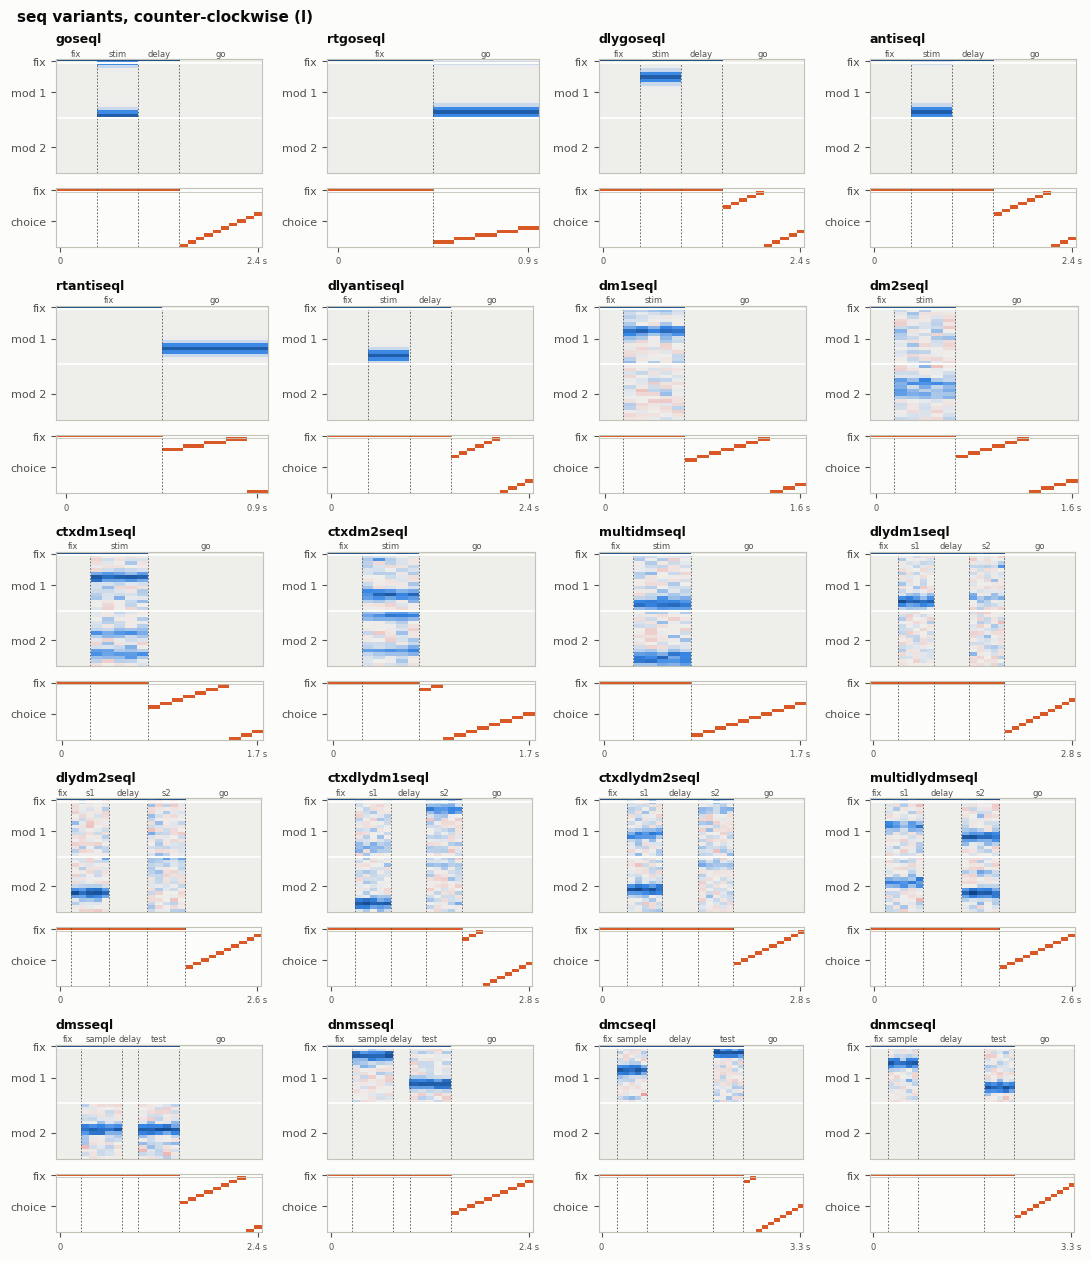

In [5]:
gallery([t for t in modcog if t.endswith("seql")], title="seq variants, counter-clockwise (l)")